In [15]:
%pip install -q "qiskit==2.2.3" "qiskit-machine-learning==0.9.0" "qiskit-algorithms==0.4.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-machine-learning", "qiskit-algorithms", "torch", "numpy", "scipy"]:
    print(name, version(name))
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
print("설치 및 import 확인 완료")

Python: 3.13.16
qiskit 2.2.3
qiskit-machine-learning 0.9.0
qiskit-algorithms 0.4.0
torch 2.11.0+cpu
numpy 2.1.3
scipy 1.16.3
설치 및 import 확인 완료


Epoch 001 | Loss: 4.2934 | Acc: 0.0%
Epoch 002 | Loss: 3.7095 | Acc: 0.0%
Epoch 003 | Loss: 3.2681 | Acc: 0.0%
Epoch 004 | Loss: 2.9166 | Acc: 0.0%
Epoch 005 | Loss: 2.6271 | Acc: 0.0%
Epoch 006 | Loss: 2.3829 | Acc: 0.0%
Epoch 007 | Loss: 2.1733 | Acc: 0.0%
Epoch 008 | Loss: 1.9908 | Acc: 0.0%
Epoch 009 | Loss: 1.8302 | Acc: 0.0%
Epoch 010 | Loss: 1.6877 | Acc: 0.0%
Epoch 011 | Loss: 1.5602 | Acc: 0.0%
Epoch 012 | Loss: 1.4456 | Acc: 0.0%
Epoch 013 | Loss: 1.3420 | Acc: 0.0%
Epoch 014 | Loss: 1.2480 | Acc: 0.0%
Epoch 015 | Loss: 1.1623 | Acc: 0.0%
Epoch 016 | Loss: 1.0839 | Acc: 0.0%
Epoch 017 | Loss: 1.0120 | Acc: 0.0%
Epoch 018 | Loss: 0.9458 | Acc: 0.0%
Epoch 019 | Loss: 0.8849 | Acc: 0.0%
Epoch 020 | Loss: 0.8286 | Acc: 0.0%
Epoch 021 | Loss: 0.7766 | Acc: 0.0%
Epoch 022 | Loss: 0.7283 | Acc: 0.0%
Epoch 023 | Loss: 0.6835 | Acc: 100.0%
Epoch 024 | Loss: 0.6418 | Acc: 100.0%
Epoch 025 | Loss: 0.6030 | Acc: 100.0%
Epoch 026 | Loss: 0.5668 | Acc: 100.0%
Epoch 027 | Loss: 0.5331 | Acc

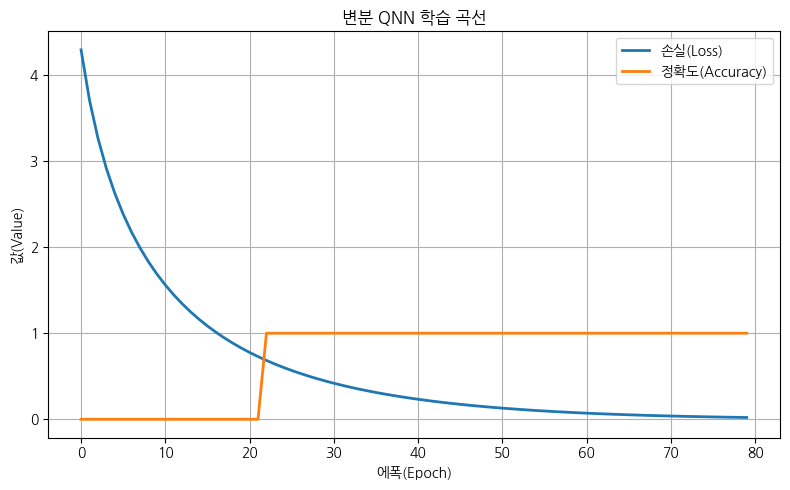


그래프가 'vqe_training_plot.png'로 저장되었습니다.
학습 정확도: 1.0
기록된 최초/최종 손실: 4.293410301208496 0.020534461364150047


In [16]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

# -----------------------------------------------------
# 0) 재현성 설정
# -----------------------------------------------------
os.environ["PYTHONHASHSEED"] = "0"
np.random.seed(42)
torch.manual_seed(42)

# -----------------------------------------------------
# 1) 데이터 (XOR)
# -----------------------------------------------------
X_np = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=np.float32)
y_np = np.array([0,1,1,0], dtype=np.float32).reshape(-1,1)

X = torch.tensor(X_np, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.float32)

# -----------------------------------------------------
# 2) 양자 회로 정의 (데이터 인코딩 + 변분 게이트)
# -----------------------------------------------------
num_qubits = 2
x_params = ParameterVector("x", length=2)
theta = ParameterVector("θ", length=4)

qc = QuantumCircuit(num_qubits)
qc.ry(np.pi * x_params[0], 0)
qc.ry(np.pi * x_params[1], 1)
qc.cx(0, 1)
qc.ry(theta[0], 0)
qc.rz(theta[1], 0)
qc.ry(theta[2], 1)
qc.rz(theta[3], 1)

# -----------------------------------------------------
# 3) Observable 설정 (출력 측정 기준)
# -----------------------------------------------------
obs = SparsePauliOp.from_list([("ZI", 1.0)])  # Qiskit의 ZI: 1번 큐비트의 Z 기댓값

# -----------------------------------------------------
# 4) EstimatorQNN 구성
# -----------------------------------------------------
primitive = StatevectorEstimator(default_precision=0.0, seed=42)
qnn = EstimatorQNN(
    circuit=qc,
    observables=obs,
    input_params=list(x_params),
    weight_params=list(theta),
    estimator=primitive,
    default_precision=0.0,
    input_gradients=True,
)

# -----------------------------------------------------
# 5) PyTorch 모델로 변환
# -----------------------------------------------------
model = TorchConnector(qnn)

# -----------------------------------------------------
# 6) 학습 설정
# -----------------------------------------------------
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.08)
epochs = 80

losses, accuracies = [], []

# -----------------------------------------------------
# 7) 학습 루프 (에폭 1단위 출력)
# -----------------------------------------------------
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    out_expect = model(X)                 # [-1, 1] 범위
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)       # [0, 1] 확률값 변환

    loss = criterion(prob, y)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        y_hat = (prob >= 0.5).float()
        acc = (y_hat.eq(y)).float().mean().item()

    losses.append(loss.item())
    accuracies.append(acc)

    print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | Acc: {acc*100:.1f}%")

# -----------------------------------------------------
# 8) 학습 결과 평가
# -----------------------------------------------------
model.eval()
with torch.no_grad():
    out_expect = model(X)
    prob = ((out_expect + 1.0) / 2.0).clamp(1e-6, 1-1e-6)
    y_pred = (prob >= 0.5).float()

print("\n[최종 결과]")
print("입력 X:\n", X_np)
print("예측 확률 p:\n", prob.numpy().round(4).flatten())
print("예측 레이블:\n", y_pred.numpy().astype(int).flatten())
print("실제 레이블:\n", y_np.flatten())

# -----------------------------------------------------
# 9) 손실 및 정확도 시각화
# -----------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(losses, label="손실(Loss)", linewidth=2)
plt.plot(accuracies, label="정확도(Accuracy)", linewidth=2)
plt.title("변분 QNN 학습 곡선")
plt.xlabel("에폭(Epoch)")
plt.ylabel("값(Value)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("vqe_training_plot.png", dpi=300)
plt.show()

print("\n그래프가 'vqe_training_plot.png'로 저장되었습니다.")

assert np.isfinite(losses).all()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
assert prob.shape == y.shape and torch.isfinite(prob).all()
assert ((prob > 0) & (prob < 1)).all()
assert losses[-1] < losses[0]
print("학습 정확도:", float((y_pred == y).float().mean()))
print("기록된 최초/최종 손실:", losses[0], losses[-1])